# 8.4 Как показать вывод на графике

Аналитика 101 · блок «Дата аналитика» · тема 08 «Визуализация в Python» · страница 8.4.

Вы построите график по месячным продажам магазина, выделите линию приложения и подпишете месяц обновления. Затем проверите заголовок по данным и сравните палитры с помощью модели дейтеранопии. Общая таблица выручки лежит в `data/viz/`.

**Как работать.** Выполняйте ячейки по порядку сверху вниз: каждый блок продолжает предыдущий.

Вывод получен на Python 3.13, NumPy 2.5, pandas 3.0 и matplotlib 3.10.

## Где лежат данные и файл стиля

Код страницы читает данные по пути от корня папки с материалами: `data/viz/sales_monthly.csv`. Ноутбук лежит в папке страницы, поэтому первая ячейка поднимается до папки, в которой есть `data/`, и делает её рабочей.

Файл стиля `textbook.mplstyle` лежит рядом с ноутбуком, а код страницы ищет его в рабочей папке. Первая ячейка кладёт туда копию. Туда же блоки сохранят рисунки `highlight.svg`, `labels.svg`, `annotated.svg` и `styled.svg`.

In [1]:
import os
import pathlib
import platform
import shutil

import matplotlib
import numpy as np
import pandas as pd

here = pathlib.Path.cwd()                   # папка ноутбука: здесь лежит textbook.mplstyle
root = here
while not (root / "data" / "viz").is_dir() and root != root.parent:
    root = root.parent                      # поднимаемся, пока рядом не окажется data/viz/
assert (root / "data" / "viz" / "sales_monthly.csv").exists(), \
    "Не найдена папка data/viz/. Скачайте общий набор темы 08 и положите data/ рядом с папкой страницы"
os.chdir(root)
if not pathlib.Path("textbook.mplstyle").exists():
    shutil.copy(here / "textbook.mplstyle", "textbook.mplstyle")   # копия стиля в рабочую папку

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__)

Python 3.13.13 | numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.10.0


## График выручки приложения

### Как выделить выручку приложения

(24, 10) — 24 месяца × 10 каналов


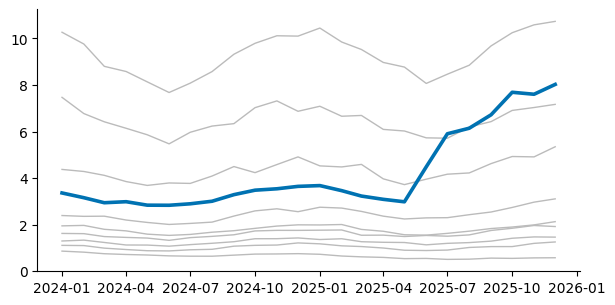

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["svg.fonttype"] = "none"  # текст в SVG остаётся текстом, а не кривыми

GREY, ACCENT = "#BBBBBB", "#0072B2"  # фон и акцент: синий из палитры Окабе — Ито

def highlight(ax, wide, key):
    """Выделяет линию key цветом и рисует её поверх остальных линий."""
    for name, s in wide.items():
        on = name == key
        ax.plot(s.index, s.values, color=ACCENT if on else GREY,
                lw=2.6 if on else 1.0, zorder=3 if on else 1)
    return ax

df = pd.read_csv("data/viz/sales_monthly.csv")
wide = df.pivot_table(index="month", columns="channel",
                      values="revenue", aggfunc="sum") / 1e6  # млн ₽
wide.index = pd.PeriodIndex(wide.index, freq="M").to_timestamp()
print(wide.shape, "— 24 месяца × 10 каналов")

fig, ax = plt.subplots(figsize=(7, 3.4))
highlight(ax, wide, "приложение")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("highlight.svg", bbox_inches="tight")

Блоки этого раздела идут подряд, как ячейки одного ноутбука: каждый следующий пользуется тем, что определено выше. Данные — общий набор data/viz/.

### Как разместить подписи у правых концов линий

                дек 2025  подпись на
channel                             
колл-центр          0.58        0.58
кешбэк-сервисы      1.26        1.38
офлайн-точки        1.46        2.18
партнёры            1.92        2.98
соцсети             2.13        3.78
рассылка            3.11        4.58
поиск               5.35        5.38
маркетплейс         7.17        7.17
приложение          8.03        8.03
сайт               10.74       10.74


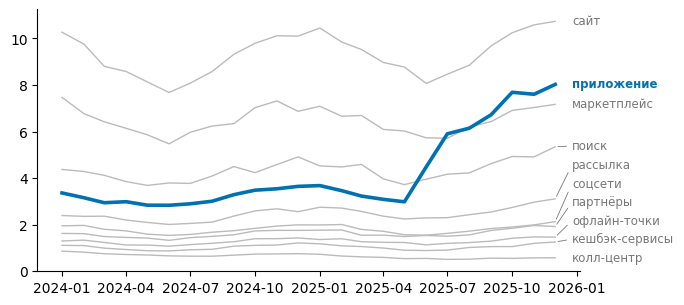

In [3]:
def label_ends(ax, wide, key, min_gap=0.8):
    """Подписывает линии и оставляет между надписями интервал в единицах шкалы Y."""
    last = wide.iloc[-1].sort_values()          # значения в последнем месяце
    ys = []
    for y in last.values:                       # снизу вверх: не ближе min_gap
        ys.append(max(y, ys[-1] + min_gap) if ys else y)
    x = wide.index[-1] + pd.Timedelta(days=24)  # чуть правее конца линий
    for (name, y0), y in zip(last.items(), ys):
        color = ACCENT if name == key else "#777777"
        connector = dict(arrowstyle="-", color=color, lw=0.6, relpos=(0, 0.5)) if y > y0 else None
        ax.annotate(name, xy=(wide.index[-1], y0), xytext=(x, y),
                    va="center", fontsize=8.5, color=color, arrowprops=connector,
                    fontweight="bold" if name == key else "normal")
    return pd.DataFrame({"дек 2025": last.round(2), "подпись на": [round(y, 2) for y in ys]})

fig, ax = plt.subplots(figsize=(7, 3.4))
highlight(ax, wide, "приложение")
print(label_ends(ax, wide, "приложение"))
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("labels.svg", bbox_inches="tight")

Выполните первый блок, чтобы определить highlight, wide, ACCENT, plt и pd.

### Как проверить заголовок и отметить месяц обновления

май → июль 2025: ×1.98; май → июль 2024: ×1.02


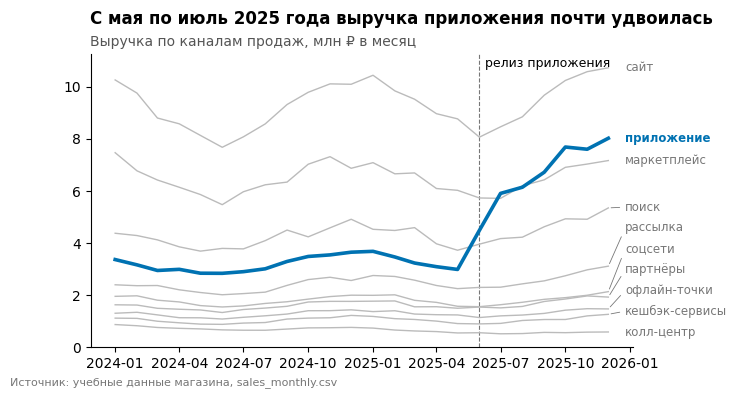

In [4]:
app = wide["приложение"]
x = app["2025-07-01"] / app["2025-05-01"]     # проверяем вывод раньше, чем пишем его
base = app["2024-07-01"] / app["2024-05-01"]  # тот же период годом раньше для сравнения
print(f"май → июль 2025: ×{x:.2f}; май → июль 2024: ×{base:.2f}")
assert 1.9 <= x < 2, "проверьте формулировку «почти удвоилась»"

release = pd.Timestamp("2025-06-01")
fig, ax = plt.subplots(figsize=(7, 3.8))
highlight(ax, wide, "приложение")
label_ends(ax, wide, "приложение")
ax.axvline(release, color="#777777", lw=0.8, ls="--", zorder=0)
ax.annotate("релиз приложения", xy=(release, 1), xycoords=("data", "axes fraction"),
            xytext=(4, -2), textcoords="offset points", va="top", fontsize=9)
ax.set_title("С мая по июль 2025 года выручка приложения почти удвоилась",
             loc="left", fontweight="bold", pad=22)
ax.text(0, 1.03, "Выручка по каналам продаж, млн ₽ в месяц",
        transform=ax.transAxes, color="#555555")
fig.text(0.01, 0.01, "Источник: учебные данные магазина, sales_monthly.csv",
         fontsize=8, color="#777777")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("annotated.svg", bbox_inches="tight")

Функции highlight и label_ends и таблица wide определены в предыдущих блоках.

### Файл стиля textbook.mplstyle: всё оформление в одном месте

Обычный текстовый файл: по строке на настройку `rcParams`. Следующий блок подключает его одной строкой.

In [5]:
print(pathlib.Path("textbook.mplstyle").read_text(encoding="utf-8"))

# textbook.mplstyle — стиль курса «Аналитика 101»
# Цвета пишутся без «#»: в этом формате «#» начинает комментарий
figure.figsize      : 7, 3.8
savefig.bbox        : tight
svg.fonttype        : none
font.family         : sans-serif
font.sans-serif     : Onest, DejaVu Sans, Arial
font.size           : 10
axes.titlesize      : 13
axes.titleweight    : bold
axes.titlelocation  : left
axes.titlepad       : 22
axes.spines.top     : False
axes.spines.right   : False
axes.edgecolor      : 888888
axes.grid           : True
axes.grid.axis      : y
grid.color          : E8E8E8
grid.linewidth      : 0.8
xtick.color         : 555555
ytick.color         : 555555
lines.linewidth     : 1.6
legend.frameon      : False
axes.prop_cycle     : cycler("color", ["0072B2", "D55E00", "009E73", "CC79A7", "E69F00", "56B4E9", "000000"])



### Стиль подключается одной строкой и действует на все графики

заголовок: left | верхняя рамка: False | палитра: ['#0072B2', '#D55E00', '#009E73']


внутри style.context('default') верхняя рамка: True


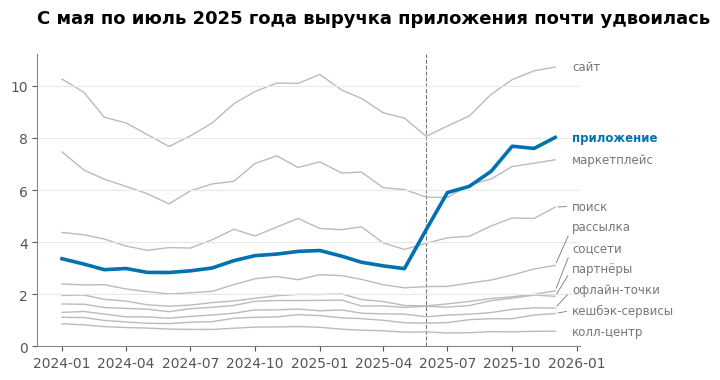

In [6]:
plt.style.use("textbook.mplstyle")  # путь к файлу; можно сохранить в stylelib и подключать по имени
print("заголовок:", plt.rcParams["axes.titlelocation"],
      "| верхняя рамка:", plt.rcParams["axes.spines.top"],
      "| палитра:", plt.rcParams["axes.prop_cycle"].by_key()["color"][:3])

fig, ax = plt.subplots()             # рамки, сетка, шрифт и заголовок — уже из стиля
highlight(ax, wide, "приложение")
label_ends(ax, wide, "приложение")
ax.axvline(release, color="#777777", lw=0.8, ls="--", zorder=0)
ax.set_title("С мая по июль 2025 года выручка приложения почти удвоилась")
fig.savefig("styled.svg")

with plt.style.context("default"):   # временно вернуть стандартный вид
    print("внутри style.context('default') верхняя рамка:", plt.rcParams["axes.spines.top"])

Продолжение: highlight, label_ends, wide и release — из блоков выше; файл textbook.mplstyle должен лежать в рабочей папке.

### В модели дейтеранопии четыре пары оттенков tab10 близки по цвету

In [7]:
import numpy as np
from itertools import combinations
from matplotlib.colors import to_rgb

# Матрица Machado и др. (2009) для дейтеранопии, применяется к линейному RGB
M = np.array([[0.367322, 0.860646, -0.227968],
              [0.280085, 0.672501, 0.047413],
              [-0.011820, 0.042940, 0.968881]])
XYZ = np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]])

def lab(hex_, deut=False):
    c = np.array(to_rgb(hex_))
    c = np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)  # sRGB → линейный
    if deut:
        c = np.clip(M @ c, 0, 1)
    t = XYZ @ c / np.array([0.95047, 1.0, 1.08883])
    f = np.where(t > 0.008856, np.cbrt(t), 7.787 * t + 16 / 116)
    return np.array([116 * f[1] - 16, 500 * (f[0] - f[1]), 200 * (f[1] - f[2])])

def merged(pal, thr=10):
    """Пары цветов, которые после моделирования дейтеранопии ближе thr по ΔE (CIELAB)."""
    return [f"{a}~{b}" for a, b in combinations(pal, 2)
            if np.linalg.norm(lab(a, True) - lab(b, True)) < thr]

palettes = {
    "tab10 (по умолчанию)": ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd",
                             "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"],
    "цвета интерфейса": ["#2f6db5", "#d27a12", "#17895f", "#c2417a",
                        "#7b5bd6", "#a8860f", "#23919f"],
    "стиль учебника": plt.rcParams["axes.prop_cycle"].by_key()["color"],
    "серый + акцент": [GREY, ACCENT],
}
for name, pal in palettes.items():
    pairs = merged(pal)
    print(f"{name:21} {len(pal):2} цветов, близких пар {len(pairs)}: {' '.join(pairs) or '—'}")

tab10 (по умолчанию)  10 цветов, близких пар 4: #1f77b4~#9467bd #ff7f0e~#bcbd22 #2ca02c~#d62728 #e377c2~#17becf
цвета интерфейса       7 цветов, близких пар 2: #d27a12~#a8860f #17895f~#c2417a
стиль учебника         7 цветов, близких пар 0: —
серый + акцент         2 цветов, близких пар 0: —


Продолжение: plt, GREY и ACCENT — из первого блока, палитра стиля — из подключённого textbook.mplstyle.